# Proyek Klasifikasi Gambar: Intel Image Classification
- **Nama:** Muhammad Ilham
- **Email:** ilhamswallow@gmail.com
- **ID Dicoding:** ilham0a

## Import Semua Packages/Library yang Digunakan

In [1]:
import os, glob, shutil
from collections import Counter

import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import PIL
from PIL import Image
import sklearn
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras import layers, models

SEED = 42
tf.keras.utils.set_random_seed(SEED)

gpus = tf.config.list_physical_devices('GPU')

## Data Preparation

### Data Loading

Dataset yang digunakan adalah **Intel Image Classification** (Kaggle, `puneet6060/intel-image-classification`): gambar pemandangan alam dan perkotaan dengan 6 kelas (`buildings`, `forest`, `glacier`, `mountain`, `sea`, `street`). Dataset bawaan terbagi menjadi `seg_train` dan `seg_test`;

In [2]:
!pip install -q kagglehub
import kagglehub

path = kagglehub.dataset_download('puneet6060/intel-image-classification')
print(path)

Using Colab cache for faster access to the 'intel-image-classification' dataset.
/kaggle/input/intel-image-classification


In [3]:
def find_split(name):
    for p in glob.glob(f'{path}/**/{name}/buildings', recursive=True):
        return os.path.dirname(p)

TRAIN_DIR = find_split('seg_train')
TEST_DIR = find_split('seg_test')
print('Folder train:', TRAIN_DIR)
print('Folder test :', TEST_DIR)
assert TRAIN_DIR and TEST_DIR, 'Folder seg_train / seg_test tidak ditemukan'

sizes = Counter()
counts = {}
for split_name, d in [('train', TRAIN_DIR), ('test', TEST_DIR)]:
    for cls in sorted(os.listdir(d)):
        files = os.listdir(os.path.join(d, cls))
        counts[(split_name, cls)] = len(files)
        for f in files:
            with Image.open(os.path.join(d, cls, f)) as im:
                sizes[im.size] += 1

print('\nJumlah gambar per kelas:')
for (split_name, cls), n in counts.items():
    print(f'  {split_name:5s} {cls:10s} {n}')

total = sum(sizes.values())
dominant_size, dominant_n = sizes.most_common(1)[0]
print(f'\nTotal gambar            : {total}')
print(f'Jumlah resolusi unik    : {len(sizes)}')
print(f'Resolusi terbanyak      : {dominant_size} = {dominant_n} gambar ({dominant_n / total:.2%})')
print('Resolusi lainnya (10 teratas):', sizes.most_common(11)[1:])

Folder train: /kaggle/input/intel-image-classification/seg_train/seg_train
Folder test : /kaggle/input/intel-image-classification/seg_test/seg_test

Jumlah gambar per kelas:
  train buildings  2191
  train forest     2271
  train glacier    2404
  train mountain   2512
  train sea        2274
  train street     2382
  test  buildings  437
  test  forest     474
  test  glacier    553
  test  mountain   525
  test  sea        510
  test  street     501

Total gambar            : 17034
Jumlah resolusi unik    : 32
Resolusi terbanyak      : (150, 150) = 16979 gambar (99.68%)
Resolusi lainnya (10 teratas): [((150, 113), 7), ((150, 135), 3), ((150, 111), 3), ((150, 136), 2), ((150, 108), 2), ((150, 149), 2), ((150, 110), 2), ((150, 143), 2), ((150, 142), 2), ((150, 76), 2)]


Contoh satu gambar dari setiap kelas.

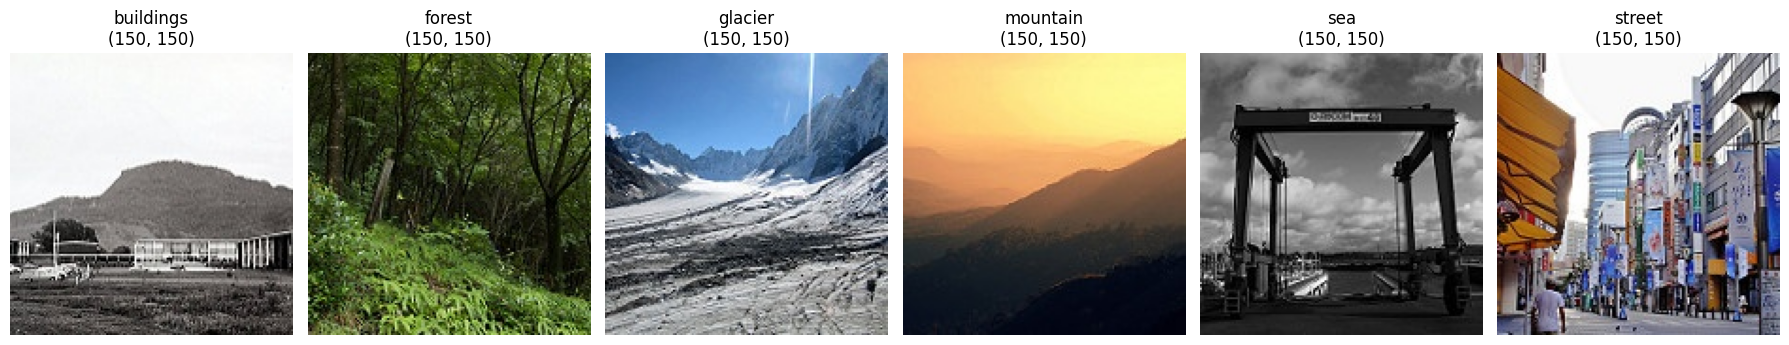

In [4]:
classes_all = sorted(os.listdir(TRAIN_DIR))
fig, axes = plt.subplots(1, len(classes_all), figsize=(3 * len(classes_all), 3.4))
for ax, cls in zip(axes, classes_all):
    f = sorted(os.listdir(os.path.join(TRAIN_DIR, cls)))[0]
    img = Image.open(os.path.join(TRAIN_DIR, cls, f))
    ax.imshow(img)
    ax.set_title(f'{cls}\n{img.size}')
    ax.axis('off')
plt.tight_layout()
plt.show()

### Data Preprocessing

#### Split Dataset

Karena dataset bawaan sudah terbagi menjadi `seg_train` dan `seg_test`, pembagiannya dilakukan ulang secara manual dengan langkah berikut:

1. **Gabungkan** seluruh gambar dari `seg_train` dan `seg_test` ke satu folder per kelas, sambil membuang gambar duplikat persis (berdasarkan hash MD5 isi berkas).
2. **Bagi** setiap kelas secara acak (seed tetap) menjadi **train 80%**, **validation 10%**, dan **test 10%**, sehingga proporsi kelas di setiap bagian tetap seimbang.
3. **Verifikasi** jumlah gambar dan pastikan tidak ada gambar yang sama di lebih dari satu bagian.

Gambar diubah ke ukuran 128x128 hanya di pipeline pemuatan data, tanpa mengubah berkas aslinya. Augmentasi berada di dalam model sebagai layer acak yang hanya aktif saat training, jadi data validation dan test tidak pernah diaugmentasi.

####Gabungkan seluruh data dan buang duplikat

In [5]:
import hashlib

ALL_DIR = '/content/dataset_all'        # seluruh gambar digabung per kelas
SPLIT_DIR = '/content/dataset_split'    # hasil pembagian train / validation / test
for d in (ALL_DIR, SPLIT_DIR):
    shutil.rmtree(d, ignore_errors=True)

def md5(path):
    h = hashlib.md5()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(1 << 20), b''):
            h.update(chunk)
    return h.hexdigest()

seen_hashes = set()
n_before, n_duplicates = 0, 0
for src_name, src_dir in [('train', TRAIN_DIR), ('test', TEST_DIR)]:
    for cls in sorted(os.listdir(src_dir)):
        os.makedirs(f'{ALL_DIR}/{cls}', exist_ok=True)
        for fname in sorted(os.listdir(f'{src_dir}/{cls}')):
            n_before += 1
            path = f'{src_dir}/{cls}/{fname}'
            h = md5(path)
            if h in seen_hashes:
                n_duplicates += 1
                continue
            seen_hashes.add(h)
            shutil.copy2(path, f'{ALL_DIR}/{cls}/{src_name}_{fname}')

print(f'Gambar sebelum digabung : {n_before}')
print(f'Duplikat persis dibuang : {n_duplicates}')
print(f'Gambar setelah digabung : {n_before - n_duplicates}')
print('\nJumlah gambar per kelas setelah digabung:')
for cls in sorted(os.listdir(ALL_DIR)):
    print(f'  {cls:10s} {len(os.listdir(f"{ALL_DIR}/{cls}"))}')

Gambar sebelum digabung : 17034
Duplikat persis dibuang : 18
Gambar setelah digabung : 17016

Jumlah gambar per kelas setelah digabung:
  buildings  2627
  forest     2743
  glacier    2956
  mountain   3031
  sea        2782
  street     2877


#### Bagi menjadi train, validation, dan test

In [6]:
from sklearn.model_selection import train_test_split

# pembagian per kelas (stratified): 80% train, 10% validation, 10% test
split_files = {'train': {}, 'validation': {}, 'test': {}}
for cls in sorted(os.listdir(ALL_DIR)):
    files = sorted(os.listdir(f'{ALL_DIR}/{cls}'))
    train_f, rest_f = train_test_split(files, test_size=0.2, random_state=SEED)
    val_f, test_f = train_test_split(rest_f, test_size=0.5, random_state=SEED)
    split_files['train'][cls] = train_f
    split_files['validation'][cls] = val_f
    split_files['test'][cls] = test_f

for split_name, per_class in split_files.items():
    for cls, files in per_class.items():
        os.makedirs(f'{SPLIT_DIR}/{split_name}/{cls}', exist_ok=True)
        for fname in files:
            shutil.copy2(f'{ALL_DIR}/{cls}/{fname}', f'{SPLIT_DIR}/{split_name}/{cls}/{fname}')

# ringkasan jumlah gambar
classes_sorted = sorted(os.listdir(ALL_DIR))
print(f'{"kelas":10s} {"train":>7s} {"val":>7s} {"test":>7s}')
for cls in classes_sorted:
    print(f'{cls:10s} {len(split_files["train"][cls]):7d} '
          f'{len(split_files["validation"][cls]):7d} {len(split_files["test"][cls]):7d}')

totals = {k: sum(len(v) for v in per_class.values()) for k, per_class in split_files.items()}
n_all = sum(totals.values())
print()
for k, n in totals.items():
    print(f'{k:10s}: {n} gambar ({n / n_all:.1%})')

kelas        train     val    test
buildings     2101     263     263
forest        2194     274     275
glacier       2364     296     296
mountain      2424     303     304
sea           2225     278     279
street        2301     288     288

train     : 13609 gambar (80.0%)
validation: 1702 gambar (10.0%)
test      : 1705 gambar (10.0%)


####  Verifikasi tidak ada gambar yang sama di lebih dari satu bagian

In [7]:
split_hashes = {}
for split_name in ['train', 'validation', 'test']:
    hs = []
    for cls in classes_sorted:
        folder = f'{SPLIT_DIR}/{split_name}/{cls}'
        hs.extend(md5(f'{folder}/{f}') for f in os.listdir(folder))
    split_hashes[split_name] = hs

for name, hs in split_hashes.items():
    print(f'{name:10s}: {len(hs)} berkas, {len(set(hs))} isi unik')

assert all(len(hs) == len(set(hs)) for hs in split_hashes.values()), 'Ada duplikat di dalam satu bagian'
assert set(split_hashes['train']).isdisjoint(split_hashes['validation']), 'train dan validation tumpang tindih'
assert set(split_hashes['train']).isdisjoint(split_hashes['test']), 'train dan test tumpang tindih'
assert set(split_hashes['validation']).isdisjoint(split_hashes['test']), 'validation dan test tumpang tindih'
print('\nTidak ada gambar yang sama di lebih dari satu bagian.')

train     : 13609 berkas, 13609 isi unik
validation: 1702 berkas, 1702 isi unik
test      : 1705 berkas, 1705 isi unik

Tidak ada gambar yang sama di lebih dari satu bagian.


#### Memuat ketiga bagian sebagai dataset TensorFlow

In [8]:
IMG = (128, 128)
BATCH = 32

common = dict(image_size=IMG, batch_size=BATCH, label_mode='categorical', seed=SEED)

train_ds = tf.keras.utils.image_dataset_from_directory(f'{SPLIT_DIR}/train', shuffle=True, **common)
val_ds = tf.keras.utils.image_dataset_from_directory(f'{SPLIT_DIR}/validation', shuffle=False, **common)
test_ds = tf.keras.utils.image_dataset_from_directory(f'{SPLIT_DIR}/test', shuffle=False, **common)

CLASSES = train_ds.class_names
NUM_CLASSES = len(CLASSES)
print('Kelas:', CLASSES)
assert NUM_CLASSES == 6, f'Harusnya 6 kelas, ditemukan {NUM_CLASSES}'
assert CLASSES == val_ds.class_names == test_ds.class_names

AUTOTUNE = tf.data.AUTOTUNE
train_ds = train_ds.prefetch(AUTOTUNE)
val_ds = val_ds.prefetch(AUTOTUNE)
test_ds = test_ds.prefetch(AUTOTUNE)

Found 13609 files belonging to 6 classes.
Found 1702 files belonging to 6 classes.
Found 1705 files belonging to 6 classes.
Kelas: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


## Modelling

Model **Sequential** dengan empat blok **Conv2D** dan **MaxPooling2D**, diakhiri `GlobalAveragePooling2D` dan lapisan Dense. Callback yang dipakai:

- `ReduceLROnPlateau`: menurunkan learning rate saat loss validasi stagnan.
- `EarlyStopping`: menghentikan training saat loss validasi tidak membaik, lalu mengembalikan bobot terbaik.
- `StopAt95` (callback khusus): menghentikan training jika akurasi train dan validasi sama-sama mencapai 95%.

In [9]:
model = models.Sequential([
    layers.Input(shape=IMG + (3,)),

    # augmentasi: hanya aktif saat training
    layers.RandomFlip('horizontal'),
    layers.RandomRotation(0.05),
    layers.RandomZoom(0.1),
    layers.Rescaling(1./255),

    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(32, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.Conv2D(128, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D(),

    layers.Conv2D(256, 3, padding='same', activation='relu'),
    layers.BatchNormalization(),
    layers.GlobalAveragePooling2D(),

    layers.Dense(256, activation='relu'),
    layers.Dropout(0.4),
    layers.Dense(NUM_CLASSES, activation='softmax'),
])

model.compile(optimizer=tf.keras.optimizers.Adam(1e-3),
              loss='categorical_crossentropy',
              metrics=['accuracy'])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ random_flip (RandomFlip)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_rotation                 │ (None, 128, 128, 3)    │             0 │
│ (RandomRotation)                │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ random_zoom (RandomZoom)        │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ rescaling (Rescaling)           │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 128, 128, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 128, 128, 32)   │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 64, 64, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 64, 64, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 32, 32, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │             

 Total params: 652,326 (2.49 MB)

 Trainable params: 650,918 (2.48 MB)

 Non-trainable params: 1,408 (5.50 KB)

### Training

In [10]:
class StopAt95(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        logs = logs or {}
        if logs.get('accuracy', 0) >= 0.95 and logs.get('val_accuracy', 0) >= 0.95:
            print('\nAkurasi train dan validasi >= 95%, training dihentikan.')
            self.model.stop_training = True

callbacks = [
    tf.keras.callbacks.ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5),
    tf.keras.callbacks.EarlyStopping(monitor='val_loss', patience=12, restore_best_weights=True),
    StopAt95(),
]

EPOCHS = 60
history = model.fit(train_ds, validation_data=val_ds, epochs=EPOCHS, callbacks=callbacks)

Epoch 1/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 52s 96ms/step - accuracy: 0.6250 - loss: 0.9769 - val_accuracy: 0.4953 - val_loss: 1.4366 - learning_rate: 0.0010
Epoch 2/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.7496 - loss: 0.6810 - val_accuracy: 0.6304 - val_loss: 1.2088 - learning_rate: 0.0010
Epoch 3/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 42s 98ms/step - accuracy: 0.7962 - loss: 0.5698 - val_accuracy: 0.7667 - val_loss: 0.6584 - learning_rate: 0.0010
Epoch 4/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.8216 - loss: 0.5024 - val_accuracy: 0.7949 - val_loss: 0.5968 - learning_rate: 0.0010
Epoch 5/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.8319 - loss: 0.4727 - val_accuracy: 0.8149 - val_loss: 0.5261 - learning_rate: 0.0010
Epoch 6/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 41s 97ms/step - accuracy: 0.8406 - loss: 0.4450 - val_accuracy: 0.7750 - val_loss: 0.6358 - learning_rate: 0.0010
Epoch 7/60
426/426 ━━━━━━━━━━━━━━━━━━━━ 41s 96ms/step - accuracy: 0.8520 - l

## Evaluasi dan Visualisasi

### Plot akurasi dan loss

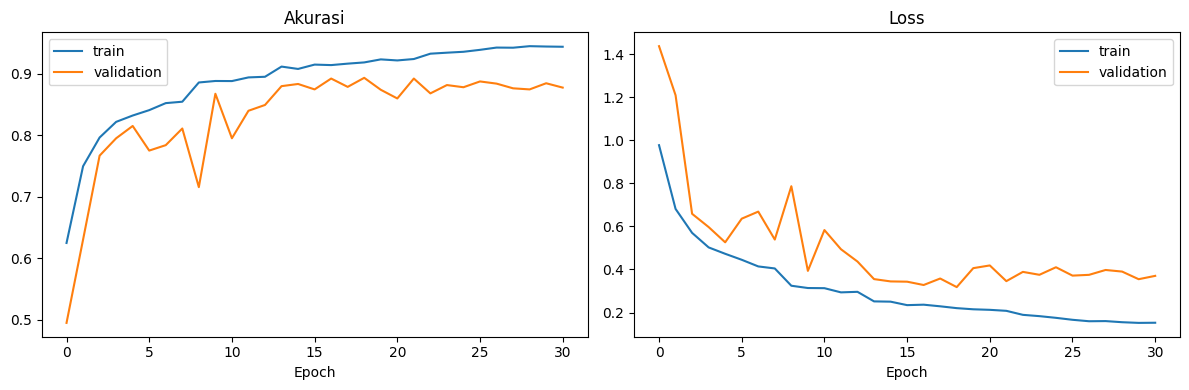

In [11]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history['accuracy'], label='train')
ax[0].plot(history.history['val_accuracy'], label='validation')
ax[0].set_title('Akurasi')
ax[0].set_xlabel('Epoch')
ax[0].legend()

ax[1].plot(history.history['loss'], label='train')
ax[1].plot(history.history['val_loss'], label='validation')
ax[1].set_title('Loss')
ax[1].set_xlabel('Epoch')
ax[1].legend()

plt.tight_layout()
plt.show()

### Akurasi akhir pada train, validation, dan test

Evaluasi dilakukan setelah training selesai (bobot terbaik), sehingga layer augmentasi tidak aktif dan akurasi train diukur pada gambar asli.

In [12]:
train_loss, train_acc = model.evaluate(train_ds, verbose=0)
val_loss, val_acc = model.evaluate(val_ds, verbose=0)
test_loss, test_acc = model.evaluate(test_ds, verbose=0)

print(f'Akurasi train      : {train_acc:.4f}')
print(f'Akurasi validation : {val_acc:.4f}')
print(f'Akurasi test       : {test_acc:.4f}')

Akurasi train      : 0.9217
Akurasi validation : 0.8931
Akurasi test       : 0.8880

Syarat wajib (>= 85% pada train dan test): TERPENUHI
Saran advance (>= 95% pada train dan test): BELUM TERPENUHI


### Classification report dan confusion matrix (test set)

              precision    recall  f1-score   support

   buildings     0.8935    0.8935    0.8935       263
      forest     0.9710    0.9745    0.9728       275
     glacier     0.8362    0.8277    0.8319       296
    mountain     0.8182    0.8586    0.8379       304
         sea     0.9101    0.8710    0.8901       279
      street     0.9129    0.9097    0.9113       288

    accuracy                         0.8880      1705
   macro avg     0.8903    0.8892    0.8896      1705
weighted avg     0.8886    0.8880    0.8881      1705



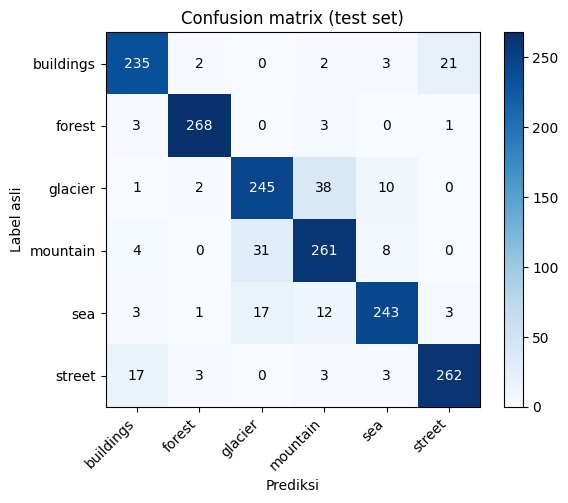

In [13]:
y_true, y_pred = [], []
for x_batch, y_batch in test_ds:
    probs = model.predict(x_batch, verbose=0)
    y_pred.extend(np.argmax(probs, axis=1))
    y_true.extend(np.argmax(y_batch.numpy(), axis=1))

print(classification_report(y_true, y_pred, target_names=CLASSES, digits=4))

cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap='Blues')
ax.set_xticks(range(NUM_CLASSES))
ax.set_yticks(range(NUM_CLASSES))
ax.set_xticklabels(CLASSES, rotation=45, ha='right')
ax.set_yticklabels(CLASSES)
ax.set_xlabel('Prediksi')
ax.set_ylabel('Label asli')
ax.set_title('Confusion matrix (test set)')
for i in range(NUM_CLASSES):
    for j in range(NUM_CLASSES):
        ax.text(j, i, cm[i, j], ha='center', va='center',
                color='white' if cm[i, j] > cm.max() / 2 else 'black')
plt.colorbar(im)
plt.tight_layout()
plt.show()

## Konversi Model

In [14]:
SUB = '/content/submission'
os.makedirs(SUB, exist_ok=True)

# Model untuk ekspor: layer augmentasi dibuang karena hanya dipakai saat training.
# Layer lainnya dipakai bersama (bobot sama), jadi hasil prediksinya identik.
start = next(i for i, l in enumerate(model.layers) if isinstance(l, layers.Rescaling))
export_model = models.Sequential([layers.Input(shape=IMG + (3,))] + model.layers[start:])

x_check, _ = next(iter(test_ds))
diff = np.abs(export_model.predict(x_check, verbose=0) - model.predict(x_check, verbose=0)).max()
print('Selisih output model vs export_model:', diff)

SAVED_MODEL_DIR = f'{SUB}/saved_model'
if os.path.exists(SAVED_MODEL_DIR):
    shutil.rmtree(SAVED_MODEL_DIR)

try:
    export_model.export(SAVED_MODEL_DIR)
except AttributeError:
    tf.saved_model.save(export_model, SAVED_MODEL_DIR)

print(sorted(os.listdir(SAVED_MODEL_DIR)))

Selisih output model vs export_model: 1.7881393e-07
Saved artifact at '/content/submission/saved_model'. The following endpoints are available:

* Endpoint 'serve'
  args_0 (POSITIONAL_ONLY): TensorSpec(shape=(None, 128, 128, 3), dtype=tf.float32, name='keras_tensor_26')
Output Type:
  TensorSpec(shape=(None, 6), dtype=tf.float32, name=None)
Captures:
  134401808725776: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808726736: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808726352: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808726160: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808724432: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808726544: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808727120: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808725584: TensorSpec(shape=(), dtype=tf.resource, name=None)
  134401808727504: TensorSpec(shape=(), dtype=tf.resource, name=None)
  13440180872731

### TF-Lite

In [15]:
converter = tf.lite.TFLiteConverter.from_saved_model(SAVED_MODEL_DIR)
tflite_model = converter.convert()

TFLITE_DIR = f'{SUB}/tflite'
os.makedirs(TFLITE_DIR, exist_ok=True)

with open(f'{TFLITE_DIR}/model.tflite', 'wb') as f:
    f.write(tflite_model)

# urutan label harus sama dengan indeks kelas pada model
with open(f'{TFLITE_DIR}/label.txt', 'w') as f:
    f.write('\n'.join(CLASSES))

print('Ukuran model.tflite:', round(len(tflite_model) / 1024, 1), 'KB')
print('Label:', CLASSES)

Ukuran model.tflite: 2553.9 KB
Label: ['buildings', 'forest', 'glacier', 'mountain', 'sea', 'street']


### TFJS


In [16]:
import subprocess, sys

TFJS_VERSION = '4.22.0'
VENV = '/content/tfjs_env'
STUB = '/content/tfjs_stub'
TFJS_DIR = f'{SUB}/tfjs_model'

def sh(cmd, env=None):
    p = subprocess.Popen(cmd, shell=True, env=env, stdout=subprocess.PIPE,
                         stderr=subprocess.STDOUT, text=True)
    for line in p.stdout:
        print(line, end='')
    return p.wait()

def must(cmd):
    if sh(cmd) != 0:
        raise RuntimeError(f'Perintah gagal: {cmd}')

print('[1/4] Membuat lingkungan Python terpisah ...')
shutil.rmtree(VENV, ignore_errors=True)
must('pip install -q uv')
must(f'uv venv {VENV} --python {sys.executable} -q')
PY = f'{VENV}/bin/python'

print('[2/4] Memasang paket konverter (sekitar 2-5 menit) ...')
must(f'uv pip install -q --python {PY} tensorflow-cpu jax jaxlib flax tensorflow-hub tf-keras '
     f'importlib_resources six packaging "setuptools<81"')
must(f'uv pip install -q --python {PY} --no-deps "tensorflowjs=={TFJS_VERSION}"')

print('[3/4] Menyiapkan modul pengganti tensorflow_decision_forests ...')
os.makedirs(f'{STUB}/tensorflow_decision_forests', exist_ok=True)
open(f'{STUB}/tensorflow_decision_forests/__init__.py', 'w').close()

print('[4/4] Mengonversi SavedModel ke TFJS (sekitar 1-3 menit) ...')
shutil.rmtree(TFJS_DIR, ignore_errors=True)
env = dict(os.environ, PYTHONPATH=STUB, CUDA_VISIBLE_DEVICES='-1',
           JAX_PLATFORMS='cpu', TF_CPP_MIN_LOG_LEVEL='2')
exit_code = sh(
    f'{VENV}/bin/tensorflowjs_converter --input_format=tf_saved_model '
    f'--output_format=tfjs_graph_model --signature_name=serving_default '
    f'--saved_model_tags=serve {SAVED_MODEL_DIR} {TFJS_DIR}', env=env)

if exit_code == 0 and os.path.exists(f'{TFJS_DIR}/model.json'):
    print('\nKonversi TFJS berhasil:', sorted(os.listdir(TFJS_DIR)))
else:
    raise RuntimeError(f'Konversi TFJS gagal (exit code {exit_code}), lihat output di atas')

[1/4] Membuat lingkungan Python terpisah ...
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.3/17.3 MB 98.1 MB/s eta 0:00:00
[2/4] Memasang paket konverter (sekitar 2-5 menit) ...
[3/4] Menyiapkan modul pengganti tensorflow_decision_forests ...
[4/4] Mengonversi SavedModel ke TFJS (sekitar 1-3 menit) ...
I0000 00:00:1792028225.096649   13496 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1792028233.643211   13496 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
/content/tfjs_env/lib/python3.13/site-packages/tensorflow_hub/__init__.py:61: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  from pkg_resources import parse_version
E0000 00:00:1792028236.901731   13496 cuda_platform.cc:52] failed call to cuInit: INT

## Inference

Input : [  1 128 128   3] <class 'numpy.float32'>
Output: [1 6] <class 'numpy.float32'>


/usr/local/lib/python3.13/dist-packages/tensorflow/lite/python/interpreter.py:457: UserWarning:     Warning: tf.lite.Interpreter is deprecated and is scheduled for deletion in
    TF 2.20. Please use the LiteRT interpreter from the ai_edge_litert package.
    See the [migration guide](https://ai.google.dev/edge/litert/migration)
    for details.
    
  warnings.warn(_INTERPRETER_DELETION_WARNING)


Akurasi TF-Lite pada test set: 0.8880 (1514/1705)


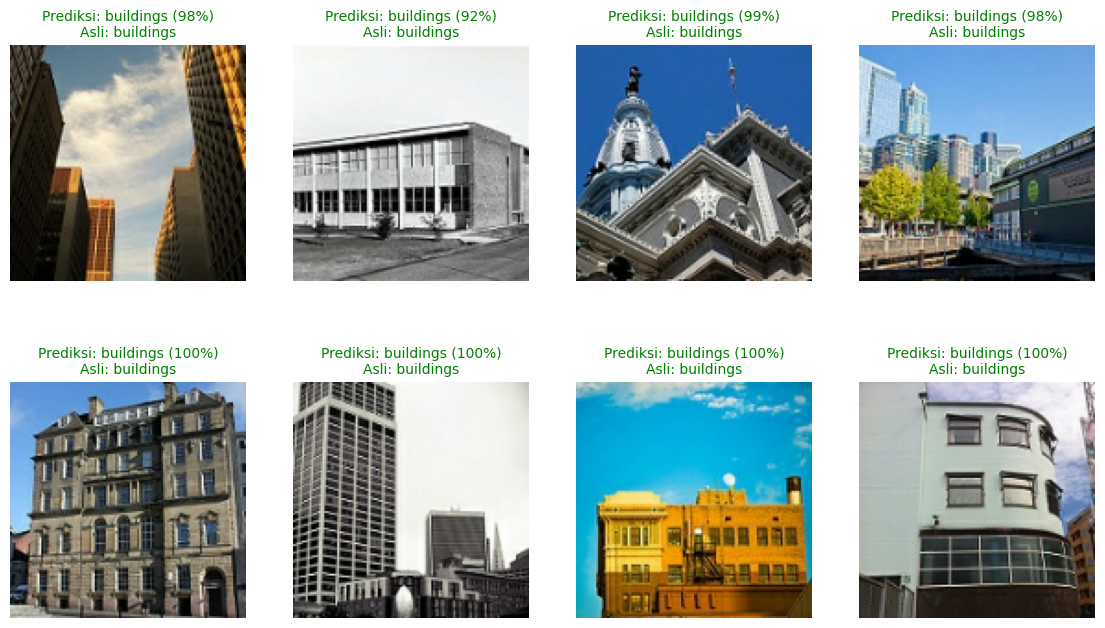

In [17]:
interpreter = tf.lite.Interpreter(model_path=f'{TFLITE_DIR}/model.tflite')
interpreter.allocate_tensors()
inp = interpreter.get_input_details()[0]
out = interpreter.get_output_details()[0]
print('Input :', inp['shape'], inp['dtype'])
print('Output:', out['shape'], out['dtype'])

with open(f'{TFLITE_DIR}/label.txt') as f:
    labels = f.read().splitlines()

def predict_tflite(img):
    x = np.expand_dims(img.astype(np.float32), axis=0)   # (1, 128, 128, 3), nilai piksel 0-255
    interpreter.set_tensor(inp['index'], x)
    interpreter.invoke()
    return interpreter.get_tensor(out['index'])[0]

correct, total_n = 0, 0
samples = []
for x_batch, y_batch in test_ds:
    for img, lab in zip(x_batch.numpy(), y_batch.numpy()):
        probs = predict_tflite(img)
        pred, true = int(np.argmax(probs)), int(np.argmax(lab))
        correct += int(pred == true)
        total_n += 1
        if len(samples) < 8:
            samples.append((img, true, pred, float(probs[pred])))

print(f'Akurasi TF-Lite pada test set: {correct / total_n:.4f} ({correct}/{total_n})')

fig, axes = plt.subplots(2, 4, figsize=(14, 7.5))
for ax, (img, true, pred, conf) in zip(axes.ravel(), samples):
    ax.imshow(img.astype('uint8'))
    ok = pred == true
    ax.set_title(f'Prediksi: {labels[pred]} ({conf:.0%})\nAsli: {labels[true]}',
                 color='green' if ok else 'red', fontsize=10)
    ax.axis('off')
plt.subplots_adjust(hspace=0.4)
plt.show()